# Analysis of pre-processed data of Consumer Complaint

The Consumer Complaint Database is a collection of complaints about consumer financial products and services that we sent to companies for response. Complaints are published after the company responds, confirming a commercial relationship with the consumer, or after 15 days, whichever comes first.

# Load the data processed into parquet beforehand

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
df = pd.read_parquet('https://cfpb-project-742435394310-us-east-1-an.s3.us-east-1.amazonaws.com/raw/raw.parquet')

**Analyzing data and datatypes and changing to the efficient ones**
---



In [ ]:
df.head()

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
0,2020-07-06,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Information belongs to someone else,None,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,FL,346XX,None,Other,Web,2020-07-06,Closed with explanation,True,N/A,3730948
1,2019-12-26,Credit card or prepaid card,General-purpose credit card or charge card,"Advertising and marketing, including promotion...",Confusing or misleading advertising about the ...,None,None,CAPITAL ONE FINANCIAL CORPORATION,CA,94025,None,Consent not provided,Web,2019-12-26,Closed with explanation,True,N/A,3477549
2,2020-05-08,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Information belongs to someone else,These are not my accounts.,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,NV,89030,None,Consent provided,Web,2020-05-08,Closed with explanation,True,N/A,3642453
3,2024-01-05,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Information belongs to someone else,Kindly address this issue on my credit report....,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,IL,60502,None,Consent provided,Web,2024-01-05,Closed with non-monetary relief,True,N/A,8113747
4,2024-01-21,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't...,None,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,NC,27401,Servicemember,Consent not provided,Web,2024-01-21,Closed with explanation,True,N/A,8191825


In [ ]:
df.shape

(14350572, 18)

In [ ]:
df.dtypes

,0
Date received,object
Product,object
Sub-product,object
Issue,object
Sub-issue,object
Consumer complaint narrative,object
Company public response,object
Company,object
State,object
ZIP code,object


In [ ]:
df.memory_usage(deep=True)

,0
Index,132
Date received,574022880
Product,1388782429
Sub-product,936668133
Issue,1256608027
Sub-issue,1211253872
Consumer complaint narrative,4252565044
Company public response,1266684365
Company,1095641605
State,730287634


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14350572 entries, 0 to 14350571
Data columns (total 18 columns):
 #   Column                        Dtype 
---  ------                        ----- 
 0   Date received                 object
 1   Product                       object
 2   Sub-product                   object
 3   Issue                         object
 4   Sub-issue                     object
 5   Consumer complaint narrative  object
 6   Company public response       object
 7   Company                       object
 8   State                         object
 9   ZIP code                      object
 10  Tags                          object
 11  Consumer consent provided?    object
 12  Submitted via                 object
 13  Date sent to company          object
 14  Company response to consumer  object
 15  Timely response?              bool  
 16  Consumer disputed?            object
 17  Complaint ID                  int64 
dtypes: bool(1), int64(1), object(16)
memory 

In [ ]:
df[df.columns] = df[df.columns].astype('category')

In [ ]:
df.memory_usage(deep=True)

,0
Index,132
Date received,29042760
Product,14352705
Sub-product,14358720
Issue,28719490
Sub-issue,28733537
Consumer complaint narrative,3257051639
Company public response,14352234
Company,29550952
State,14355923


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14350572 entries, 0 to 14350571
Data columns (total 18 columns):
 #   Column                        Dtype   
---  ------                        -----   
 0   Date received                 category
 1   Product                       category
 2   Sub-product                   category
 3   Issue                         category
 4   Sub-issue                     category
 5   Consumer complaint narrative  category
 6   Company public response       category
 7   Company                       category
 8   State                         category
 9   ZIP code                      category
 10  Tags                          category
 11  Consumer consent provided?    category
 12  Submitted via                 category
 13  Date sent to company          category
 14  Company response to consumer  category
 15  Timely response?              category
 16  Consumer disputed?            category
 17  Complaint ID                  category
dtype

The change to the category allowed to the **decrease in memory usage about: 0.7 GB**

**Analysis of NA values and their source**
---



In [ ]:
df.isnull().sum()

,0
Date received,0
Product,0
Sub-product,235277
Issue,6
Sub-issue,897315
Consumer complaint narrative,10593813
Company public response,6589068
Company,0
State,60292
ZIP code,30216


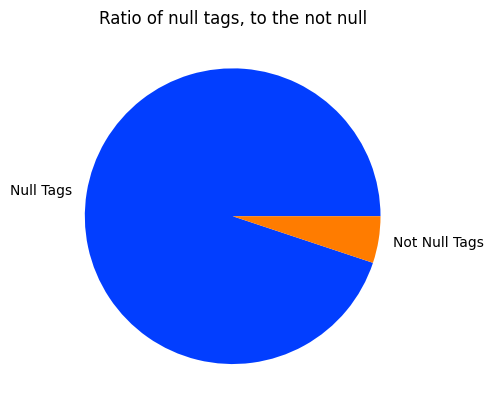

In [ ]:
data_pie_chart = [df['Tags'].isnull().sum(), df.shape[0] - df['Tags'].isnull().sum()]
labels = ['Null Tags', 'Not Null Tags']

colors = sns.color_palette('bright')

plt.pie(data_pie_chart, labels=labels,colors= colors)
plt.title('Ratio of null tags, to the not null')
plt.show()

In [ ]:
df = df.drop(['Tags'], axis = 1)

Most of the values in the Tags field are marked as Unknown, so this column is not providing useful information for analysis.

In [ ]:
df[df["Issue"].isna()]

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
3384270,2024-03-13,Checking or savings account,NaN,NaN,NaN,NaN,Company has responded to the consumer and the ...,WELLS FARGO & COMPANY,CA,93535,N/A,Referral,2024-03-14,Closed with explanation,True,N/A,8550796
5073872,2024-04-26,Credit reporting or other personal consumer re...,Credit reporting,NaN,NaN,NaN,Company believes it acted appropriately as aut...,"CCS Financial Services, Inc.",NY,11235,Consent not provided,Web,2024-04-29,Closed with non-monetary relief,True,N/A,8881244
10222126,2024-05-11,Checking or savings account,NaN,NaN,NaN,NaN,NaN,"BSI Financial Holdings, Inc.",CA,93561,N/A,Referral,2024-05-19,Closed with explanation,True,N/A,9038738
11006155,2024-04-06,Checking or savings account,NaN,NaN,NaN,NaN,Company believes it acted appropriately as aut...,NAVY FEDERAL CREDIT UNION,FL,33573,N/A,Referral,2024-04-08,Closed with explanation,True,N/A,8719062
12686724,2024-04-02,Checking or savings account,NaN,NaN,NaN,NaN,Company has responded to the consumer and the ...,WELLS FARGO & COMPANY,NY,11236,N/A,Referral,2024-04-04,Closed with explanation,True,N/A,8698781
13220462,2024-04-03,Checking or savings account,NaN,NaN,NaN,NaN,Company has responded to the consumer and the ...,"BANK OF AMERICA, NATIONAL ASSOCIATION",GA,30066,N/A,Referral,2024-04-04,Closed with explanation,True,N/A,8698636


In [ ]:
df = df.dropna(subset=["Issue"])

Since the company’s response to the consumer is the target variable for prediction, and the number of Unknown values is small, the rows with Unknown values were dropped to maintain data quality and avoid introducing noise into the model.

In [ ]:
df[df['Company response to consumer'].isna()]

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
74799,2024-04-19,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Reporting company used your report improperly,In accordance with the Fair Credit Reporting a...,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,TX,75070,Consent provided,Web,2024-04-19,NaN,True,N/A,8801950
89402,2024-03-12,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Reporting company used your report improperly,NaN,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,CA,90028,Other,Web,2024-03-12,NaN,True,N/A,8530689
1909619,2024-05-28,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Reporting company used your report improperly,"Recently I looked at my credit report, and I n...",Company has responded to the consumer and the ...,Experian Information Solutions Inc.,GA,30236,Consent provided,Web,2024-05-28,NaN,True,N/A,9109209
2481959,2021-10-21,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Information belongs to someone else,NaN,Company has responded to the consumer and the ...,"CITIBANK, N.A.",CA,91201,Consent not provided,Web,2021-10-21,NaN,True,N/A,4832902
3166411,2023-09-25,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Reporting company used your report improperly,NaN,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,IL,60478,Consent not provided,Web,2023-09-25,NaN,True,N/A,7602539
3748010,2023-05-26,Mortgage,Conventional home mortgage,Closing on a mortgage,NaN,NaN,Company believes it acted appropriately as aut...,"E Mortgage Capital, Inc.",CA,92860,Consent not provided,Web,2023-05-26,NaN,True,N/A,7035005
4234451,2024-01-03,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Reporting company used your report improperly,NaN,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,NY,10309,Consent not provided,Web,2024-01-03,NaN,True,N/A,8095891
4561689,2024-05-20,Debt collection,Other debt,Written notification about debt,Notification didn't disclose it was an attempt...,NaN,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,DE,19950,Consent not provided,Web,2024-05-20,NaN,True,N/A,9047968
5958551,2024-02-28,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't...,I am writing to delete the following informati...,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,DE,19720,Consent provided,Web,2024-02-28,NaN,True,N/A,8435816
6727588,2024-01-18,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Reporting company used your report improperly,In accordance with the Fair Credit Reporting a...,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,GA,30058,Consent provided,Web,2024-01-18,NaN,True,N/A,8166766


In [ ]:
df = df.dropna(subset=["Company response to consumer"])

In [ ]:
df['Company public response'].cat.categories

Index(['Company believes complaint caused principally by actions of third party outside the control or direction of the company',
       'Company believes complaint is the result of an isolated error',
       'Company believes complaint relates to a discontinued policy or procedure',
       'Company believes complaint represents an opportunity for improvement to better serve consumers',
       'Company believes it acted appropriately as authorized by contract or law',
       'Company believes the complaint is the result of a misunderstanding',
       'Company believes the complaint provided an opportunity to answer consumer's questions',
       'Company can't verify or dispute the facts in the complaint',
       'Company chooses not to provide a public response',
       'Company disputes the facts presented in the complaint',
       'Company has responded to the consumer and the CFPB and chooses not to provide a public response'],
      dtype='object')

In [ ]:
df[df['Sub-product'].isna()]

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
736,2013-09-21,Credit reporting,NaN,Incorrect information on credit report,Account status,NaN,NaN,Experian Information Solutions Inc.,FL,33076,N/A,Web,2013-09-21,Closed with non-monetary relief,True,Yes,535625
1136,2015-10-02,Credit card,NaN,Billing disputes,NaN,NaN,Company chooses not to provide a public response,"CITIBANK, N.A.",GA,30274,Consent not provided,Web,2015-10-02,Closed with explanation,True,No,1589985
1547,2017-02-09,Credit reporting,NaN,Incorrect information on credit report,Personal information,NaN,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,CA,94534,Consent not provided,Web,2017-02-09,Closed with non-monetary relief,True,No,2333739
1586,2016-10-26,Credit card,NaN,Billing disputes,NaN,NaN,NaN,AMERICAN EXPRESS COMPANY,NaN,NaN,N/A,Phone,2016-11-07,Closed with explanation,True,No,2180586
1713,2014-03-19,Credit reporting,NaN,Incorrect information on credit report,Information is not mine,NaN,NaN,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",CO,81504,N/A,Web,2014-03-28,Closed with non-monetary relief,True,No,765857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14350142,2013-06-17,Credit card,NaN,Other,NaN,NaN,NaN,CAPITAL ONE FINANCIAL CORPORATION,LA,70072,N/A,Phone,2013-06-18,Closed with explanation,True,No,434045
14350160,2014-12-10,Credit reporting,NaN,Incorrect information on credit report,Reinserted previously deleted info,NaN,NaN,Experian Information Solutions Inc.,FL,32615,N/A,Web,2014-12-10,Closed with explanation,True,No,1150205
14350165,2015-12-08,Credit reporting,NaN,Incorrect information on credit report,Account status,I have sent numerous letters to XXXX XXXX XXXX...,Company chooses not to provide a public response,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",MN,XXXXX,Consent provided,Web,2015-12-08,Closed with explanation,True,No,1687870
14350252,2015-09-20,Credit reporting,NaN,Incorrect information on credit report,Personal information,NaN,Company chooses not to provide a public response,Experian Information Solutions Inc.,PA,19154,Consent not provided,Web,2015-09-20,Closed with non-monetary relief,True,No,1571666


In [ ]:
df[df['Company public response'].isnull()]

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Consumer consent provided?,Submitted via,Date sent to company,Company response to consumer,Timely response?,Consumer disputed?,Complaint ID
1,2019-12-26,Credit card or prepaid card,General-purpose credit card or charge card,"Advertising and marketing, including promotion...",Confusing or misleading advertising about the ...,NaN,NaN,CAPITAL ONE FINANCIAL CORPORATION,CA,94025,Consent not provided,Web,2019-12-26,Closed with explanation,True,N/A,3477549
5,2020-03-19,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Information belongs to someone else,"I wrote three requests, the unverified account...",NaN,"EQUIFAX, INC.",NC,28562,Consent provided,Web,2020-03-19,Closed with explanation,True,N/A,3573294
7,2020-03-29,Student loan,Federal student loan servicing,Dealing with your lender or servicer,Keep getting calls about your loan,They call at all hours and on the weekends usi...,NaN,"Navient Solutions, LLC.",CA,92028,Consent provided,Web,2020-03-29,Closed with explanation,True,N/A,3584679
8,2024-01-23,Credit reporting or other personal consumer re...,Credit reporting,Problem with a company's investigation into an...,Their investigation did not fix an error on yo...,NaN,NaN,"EQUIFAX, INC.",IN,46222,Consent not provided,Web,2024-01-23,Closed with explanation,True,N/A,8207223
14,2013-10-17,Bank account or service,Checking account,Deposits and withdrawals,NaN,NaN,NaN,FIFTH THIRD FINANCIAL CORPORATION,IL,60090,N/A,Referral,2013-10-17,Closed with monetary relief,True,No,561197
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14350561,2022-03-07,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Information belongs to someone else,NaN,NaN,"EQUIFAX, INC.",NaN,XXXXX,Other,Web,2022-03-07,Closed with explanation,True,N/A,5292988
14350562,2019-07-26,Mortgage,Conventional home mortgage,Struggling to pay mortgage,NaN,NaN,NaN,JPMORGAN CHASE & CO.,NaN,NaN,N/A,Referral,2019-07-29,Closed with explanation,True,N/A,3322081
14350563,2022-02-18,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Information belongs to someone else,NaN,NaN,"EQUIFAX, INC.",NaN,XXXXX,Other,Web,2022-02-18,Closed with explanation,True,N/A,5236248
14350566,2022-04-25,"Credit reporting, credit repair services, or o...",Credit reporting,Problem with a credit reporting company's inve...,Their investigation did not fix an error on yo...,NaN,NaN,"EQUIFAX, INC.",NaN,NaN,Other,Web,2022-04-25,Closed with explanation,True,N/A,5491352


Some fields contain missing values because they are not applicable to every complaint. Not all Issues have a Sub-issue, and not all Products have a Sub-product, so missing values in these fields were filled with N/A. Similarly, Company Public Response is only available when the company chooses to publish a public-facing response. For Consumer Consent Provided?, missing values may indicate that the complaint did not meet the criteria for narrative publication, no complaint narrative was provided, or the complaint was received before March 19, 2015. Therefore, these missing values were also filled with N/A.

In [ ]:
columns_na = ['Sub-issue', 'Sub-product', 'Company public response', 'Consumer consent provided?']

for columns in columns_na:
  if 'N/A' not in df[columns].cat.categories:
    df[columns] = df[columns].cat.add_categories('N/A')

df[columns_na] = df[columns_na].fillna('N/A')

In [ ]:
zip_code_with_x = df['ZIP code'].str.contains(r'x|\(|\)', case=False, na=False).sum()

In [ ]:
proper_zip_code_precentage = df.shape[0] / (zip_code_with_x + df["ZIP code"].isnull().sum())
print(f'The precentage of proper ZIP code in data: {proper_zip_code_precentage.round(2)}')

The precentage of proper ZIP code in data: 11.72


Due to an insufficient number of valid ZIP codes, this column will be removed; and since unknown States cannot be matched to ZIP codes, the unknown States will be removed.

In [ ]:
df = df.dropna(subset = ['State'])

In [ ]:
df = df.drop(columns= ['ZIP code'])

In [ ]:
df.isnull().sum()

,0
Date received,0
Product,0
Sub-product,0
Issue,0
Sub-issue,0
Consumer complaint narrative,10546758
Company public response,0
Company,0
State,0
Consumer consent provided?,0
